## Thermal Remote Sensing Assignment

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Locate the assignment folder
folder = Path.cwd()

# Locate the data folder
data_folder = folder / "data"

# Check that the folder exists
print("Data folder found:", data_folder.exists())

# Display all text files
for file in data_folder.glob("*.txt"):
    print(file.name)


Data folder found: True
rock.igneous.felsic.fine.all.granite_h2.jhu.becknic.spectrum.txt
rock.sedimentary.carbonate.solid.tir.fge3.jpl.nicolet.spectrum.txt
water.ice.none.solid.all.ice_dat_.jhu.becknic.spectrum.txt
water.seawater.none.liquid.tir.seawater.jhu.becknic.spectrum.txt
water.snow.finegranular.fine.all.fine_snw_.jhu.becknic.spectrum.txt


### Q1: Spectral emissivity

(a)

In [2]:

# Read spectral data and convert reflectance to emissivity

def read_spectrum(filename):

    rows = []

    with open(data_folder / filename, "r", encoding="utf-8") as file:
        for line in file:
            columns = line.split()

            if len(columns) >= 2:
                try:
                    wavelength = float(columns[0])
                    reflectance = float(columns[1])
                    rows.append([wavelength, reflectance])
                except ValueError:
                    continue

    data = np.array(rows)

    wavelength = data[:, 0]
    reflectance = data[:, 1] / 100

    emissivity = 1 - reflectance

    return wavelength, emissivity


# Load all five materials

snow_x, snow_y = read_spectrum(
    "water.snow.finegranular.fine.all.fine_snw_.jhu.becknic.spectrum.txt"
)

ice_x, ice_y = read_spectrum(
    "water.ice.none.solid.all.ice_dat_.jhu.becknic.spectrum.txt"
)

water_x, water_y = read_spectrum(
    "water.seawater.none.liquid.tir.seawater.jhu.becknic.spectrum.txt"
)

limestone_x, limestone_y = read_spectrum(
    "rock.sedimentary.carbonate.solid.tir.fge3.jpl.nicolet.spectrum.txt"
)

granite_x, granite_y = read_spectrum(
    "rock.igneous.felsic.fine.all.granite_h2.jhu.becknic.spectrum.txt"
)

print("All five spectral datasets loaded successfully!")


All five spectral datasets loaded successfully!


##### (b) Plotting spectral emissivity

 Comparing the spectral emissivity of fine snow, ice and sea water in the thermal
range.

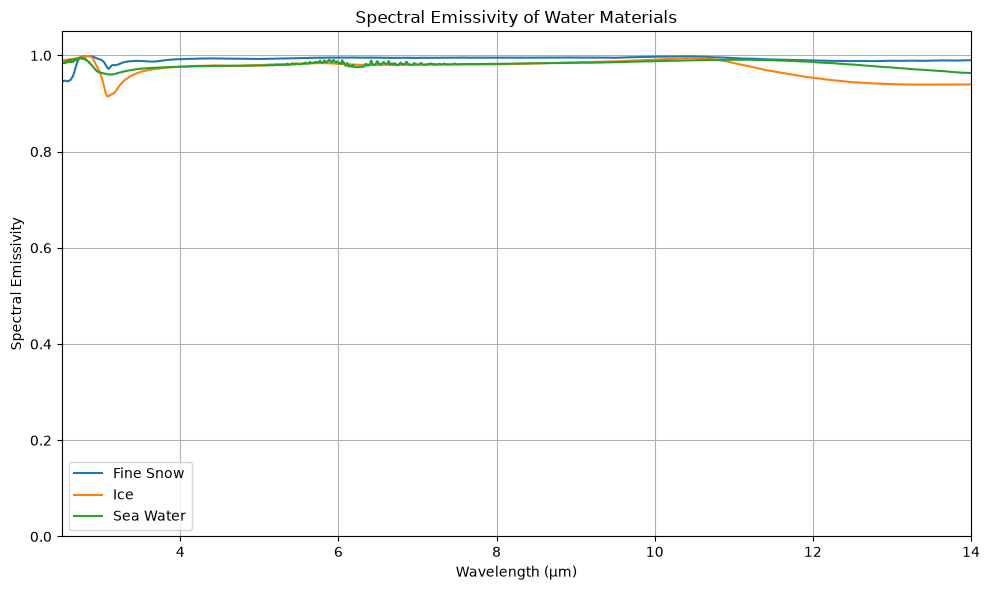

In [3]:

plt.figure(figsize=(10, 6))

plt.plot(snow_x, snow_y, label="Fine Snow")
plt.plot(ice_x, ice_y, label="Ice")
plt.plot(water_x, water_y, label="Sea Water")

plt.xlabel("Wavelength (µm)")
plt.ylabel("Spectral Emissivity")
plt.title("Spectral Emissivity of Water Materials")

plt.xlim(2.5, 14)
plt.ylim(0, 1.05)

plt.grid(True)
plt.legend()
plt.tight_layout()

plt.show()


Comparing the spectral emissivity of grey limestone and granite in the thermal
range.

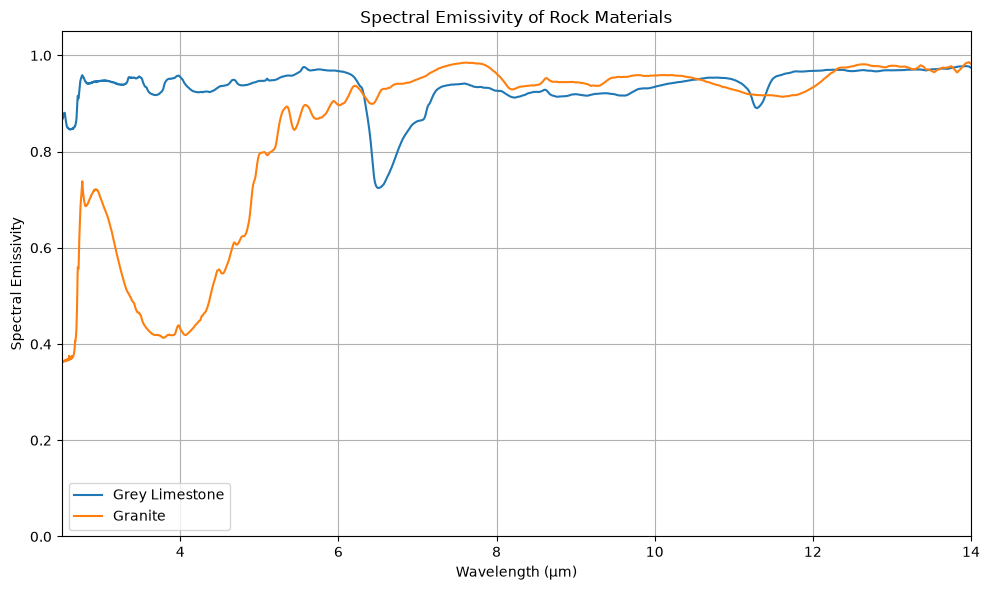

In [4]:

plt.figure(figsize=(10, 6))

plt.plot(limestone_x, limestone_y, label="Grey Limestone")
plt.plot(granite_x, granite_y, label="Granite")

plt.xlabel("Wavelength (µm)")
plt.ylabel("Spectral Emissivity")
plt.title("Spectral Emissivity of Rock Materials")

plt.xlim(2.5, 14)
plt.ylim(0, 1.05)

plt.grid(True)
plt.legend()
plt.tight_layout()

plt.show()


##### (c) Discuss the degree to which each of the five materials could be considered a blackbody, gray body or selective radiator in the thermal range. 

A blackbody is an ideal object that absorbs and emits all radiation, with an emissivity of 1 at every wavelength. A greybody has an emissivity below 1 but approximately constant across wavelengths. A selective radiator has an emissivity that changes noticeably with wavelength.

Based on the spectral emissivity curves:

- Fine snow: Fine snow can be considered close to a blackbody in much of the thermal infrared range. Its emissivity is generally high and close to 1, meaning it emits thermal radiation very efficiently. It is not a perfect blackbody because its emissivity is not exactly 1 at every wavelength.

- Ice: Ice behaves more like a greybody, as its emissivity is generally high but below 1. Its emissivity also changes with wavelength, so it is not a perfect greybody.

- Sea water: Sea water can also be considered approximately a greybody in the thermal range. Its emissivity is relatively high and does not vary as strongly as that of the rocks, although it is not completely constant.

- Grey limestone: Grey limestone is a selective radiator. Its emissivity changes with wavelength and has noticeable dips. These variations are related to the minerals and chemical bonds within the rock.

- Granite: Granite is also a selective radiator. Its emissivity varies considerably with wavelength because it contains different silicate minerals, such as quartz and feldspar, which interact with thermal infrared radiation at particular wavelengths.

Overall, snow, ice and sea water behave more like blackbodies or greybodies, while limestone and granite show more selective behaviour because of their mineral composition.

##### (d) Explanation for why dips occur at specific wavelengths in each rock type.

- Grey limestone

The grey limestone spectrum shows two noticeable emissivity dips, between approximately 6–8 µm and around 11 µm. These features are associated with vibrations of carbonate ions (CO₃²⁻) in calcite, the main mineral in limestone. The vibrations interact with thermal infrared radiation at specific wavelengths, producing lower emissivity.

Bishop, J. L., King, S. J., Lane, M. D., Brown, A. J., Lafuente, B., Hiroi, T., et al. (2021). Spectral properties of anhydrous carbonates and nitrates. Earth and Space Science, 8, e2021EA001844. https://doi.org/10.1029/2021EA001844

Liu, W., Zhang, P., Liu, C., Bo, Z., Han, D., Niu, R., & Lin, Q. (2026). Identification and quantification of minerals within Apollo samples using LWIR spectroscopy. Geo-Spatial Information Science, 29(3), 1774–1791. https://doi.org/10.1080/10095020.2025.2543970

- Granite:

The dips in the granite spectrum are caused by two different processes depending on the wavelength. Before 6 µm, the broad low emissivity is not a dip caused by vibrating atoms, but rather by energy transitions (as shown in the VNIR slides). High-energy light is absorbed when electrons in iron-bearing minerals jump to higher energy states. After 6 µm, the distinct dips around 9.2 µm and 9.8 µm occur because lower-energy infrared light matches the exact energy needed for molecular vibrations. The silicon-oxygen (Si-O) bonds in the granite's feldspar minerals absorb the light to stretch and bend, creating the specific dips that act like a chemical fingerprint.

J. Huang et al., "Thermal infrared spectrum variation and waveband features of loaded rocks with different mineral components during the fracture evolution process," Infrared Physics & Technology, vol. 137, p. 105120, 2024, doi: 10.1016/j.infrared.2024.105120.



### Q2: The impact of emissivity error

(a)

(b)

(c)

(d)

(e)

### Q3: Exploiting instantaneous temperature

(a)

(b)

### Q4: Heatwave in Paris

(a)

(b)

(c)

(d)

(e)